# Exercises XP Gold: CNN Projects

This is a guided notebook for the exercises on the platform. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear only when a concept is important for intuition or for connecting to other ML topics.

## What you will learn
- Apply CNNs to diverse image classification tasks
- Explore techniques for specific classification challenges
- Gain practical experience with different CNN functionalities

## What you will create
Four CNN based classification mini projects focused on practical application and exploration.

## How I run this notebook
I run it in Google Colab from top to bottom (a GPU runtime is faster, but it also works on a CPU). CIFAR-10 and the MobileNetV2 weights are downloaded by the code, so nothing has to be uploaded. I fix the seeds so the numbers can be repeated (on a GPU the last decimals can move a little).

I ran everything on a CPU with limited memory, so I kept some runs short and say so where it happens. Exercise 1 trains on a fixed 20,000 image subset of CIFAR-10 for 10 epochs (tested on all 10,000 test images), the augmentation ablation uses 10,000 images and 6 epochs, and the MobileNetV2 run in Exercise 3 uses a 5,000 image subset. With all 50,000 images and more epochs every accuracy here would be higher.

## Common setup

**As stated in the exercises**  
You will build classification models and explore data augmentation, overfitting prevention, transfer learning, and filter visualization.

**PREFILLED**  
Imports, version print, and utility plotting. Execute first.

In [1]:
# PREFILLED: just execute
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

def plot_history(history, title="Training"):
    plt.figure(figsize=(6,4))
    if "accuracy" in history.history: plt.plot(history.history["accuracy"], label="acc")
    if "val_accuracy" in history.history: plt.plot(history.history["val_accuracy"], label="val_acc")
    plt.title(title); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout(); plt.show()
    plt.figure(figsize=(6,4))
    if "loss" in history.history: plt.plot(history.history["loss"], label="loss")
    if "val_loss" in history.history: plt.plot(history.history["val_loss"], label="val_loss")
    plt.title(title); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.show()

TensorFlow: 2.21.0


# Exercise 1: Classifying everyday objects

**As stated in the exercises**  
Choose a dataset of everyday objects such as CIFAR-10 or your own folder dataset. Build a CNN to classify these objects and target good accuracy with a simple architecture. Experiment with data augmentation to improve robustness to lighting, angle, and position.

### 1.1 Load a dataset

**PREFILLED**  
Default uses CIFAR-10. If you use a folder dataset, replace this cell with `tf.keras.utils.image_dataset_from_directory` and adjust input size.

Train: (50000, 32, 32, 3) Test: (10000, 32, 32, 3)


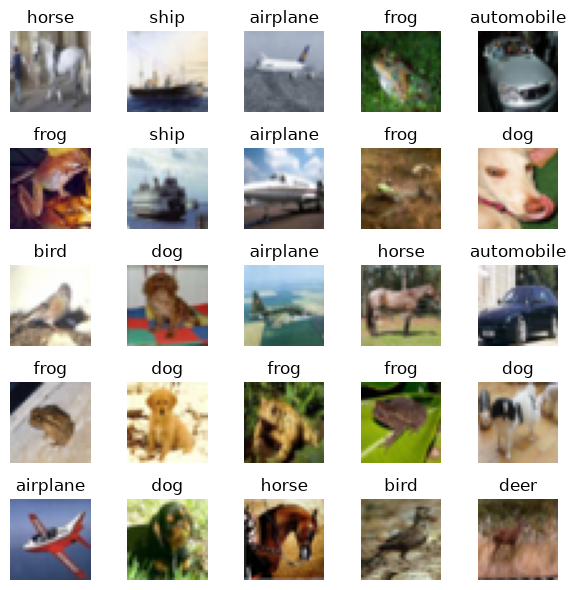

In [2]:
# PREFILLED: just execute - CIFAR-10 loader and small preview
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train = y_train.ravel(); y_test = y_test.ravel()
class_names_c10 = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
print("Train:", x_train.shape, "Test:", x_test.shape)

# show a 5x5 grid
n=25
idx = np.random.choice(len(x_train), n, replace=False)
plt.figure(figsize=(6,6))
for i,k in enumerate(idx):
    plt.subplot(5,5,i+1)
    plt.imshow(x_train[k])
    plt.title(class_names_c10[y_train[k]])
    plt.axis("off")
plt.tight_layout(); plt.show()

**Learning point**  
Data augmentation encodes invariances that your model should learn, such as small rotations and translations. This helps generalization.

### 1.2 Build a simple CNN baseline

**To-Do:** Define a compact CNN for 32x32 RGB. Use Conv2D with small kernels, MaxPooling, and a small dense head. Use `sparse_categorical_crossentropy` and track accuracy.

In [3]:
# To-Do: build and compile a baseline CNN for CIFAR-10
# I put the architecture in a function so I can build a fresh copy for each comparison
def make_cnn_e1():
    m = tf.keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Rescaling(1./255),                     # pixels 0..255 -> 0..1
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv_first"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),                        # 32x32 -> 16x16
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),                        # 16x16 -> 8x8
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),                        # 8x8 -> 4x4
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),       # one probability per class
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

tf.keras.utils.set_random_seed(42)
model_e1 = make_cnn_e1()
model_e1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_first (Conv2D)             │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,986 (1.54 MB)

 Trainable params: 402,986 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

### 1.3 Add augmentation and train

**To-Do:** Add a data augmentation block using Keras preprocessing layers such as `RandomFlip`, `RandomRotation`, and `RandomZoom`. Train for a small number of epochs, then increase if helpful. Plot curves.

First I train the same CNN **without** augmentation, so I have something to compare against.

Epoch 1/10


250/250 - 6s - 23ms/step - accuracy: 0.3371 - loss: 1.7761 - val_accuracy: 0.4173 - val_loss: 1.5588


Epoch 2/10


250/250 - 5s - 19ms/step - accuracy: 0.4899 - loss: 1.3963 - val_accuracy: 0.5132 - val_loss: 1.3017


Epoch 3/10


250/250 - 5s - 22ms/step - accuracy: 0.5683 - loss: 1.1900 - val_accuracy: 0.5815 - val_loss: 1.1502


... (10 outputs left out)

Epoch 9/10


250/250 - 10s - 38ms/step - accuracy: 0.7807 - loss: 0.6060 - val_accuracy: 0.6892 - val_loss: 0.9309


Epoch 10/10


250/250 - 4s - 17ms/step - accuracy: 0.8071 - loss: 0.5530 - val_accuracy: 0.6823 - val_loss: 0.9736


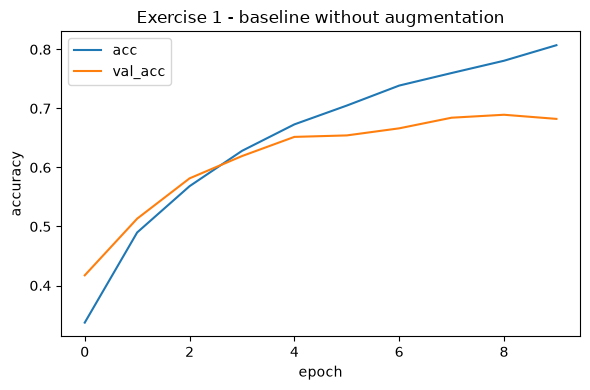

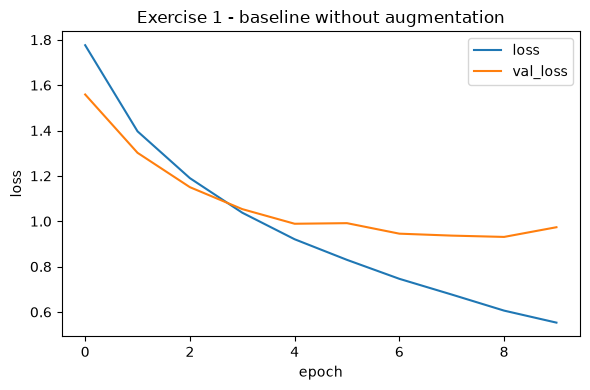

{'test_acc_no_aug': 0.6834}


In [4]:
# my CPU budget: a fixed 20,000 image training subset for Exercise 1 (16,000 train / 4,000 validation)
e1_idx = np.random.RandomState(0).choice(len(x_train), 20000, replace=False)
x_e1, y_e1 = x_train[e1_idx], y_train[e1_idx]

# reference run: same architecture, no augmentation, same 10 epochs
tf.keras.utils.set_random_seed(42)
model_noaug_e1 = make_cnn_e1()
h_noaug = model_noaug_e1.fit(x_e1, y_e1, epochs=10, batch_size=64, validation_split=0.2, verbose=2)
plot_history(h_noaug, title="Exercise 1 - baseline without augmentation")
test_acc_noaug = float(model_noaug_e1.evaluate(x_test, y_test, verbose=0)[1])
print({"test_acc_no_aug": round(test_acc_noaug, 4)})

Epoch 1/10


250/250 - 8s - 32ms/step - accuracy: 0.2865 - loss: 1.9188 - val_accuracy: 0.3688 - val_loss: 1.6668


Epoch 2/10


250/250 - 7s - 28ms/step - accuracy: 0.4029 - loss: 1.6015 - val_accuracy: 0.4358 - val_loss: 1.5161


Epoch 3/10


250/250 - 7s - 26ms/step - accuracy: 0.4577 - loss: 1.4831 - val_accuracy: 0.5033 - val_loss: 1.3746


... (10 outputs left out)

Epoch 9/10


250/250 - 6s - 24ms/step - accuracy: 0.6122 - loss: 1.0771 - val_accuracy: 0.5980 - val_loss: 1.1697


Epoch 10/10


250/250 - 6s - 25ms/step - accuracy: 0.6283 - loss: 1.0455 - val_accuracy: 0.6150 - val_loss: 1.0893


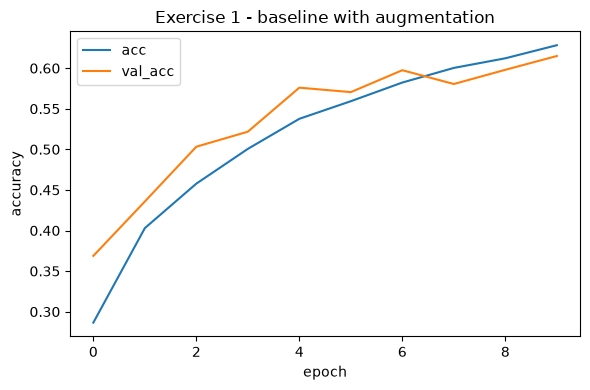

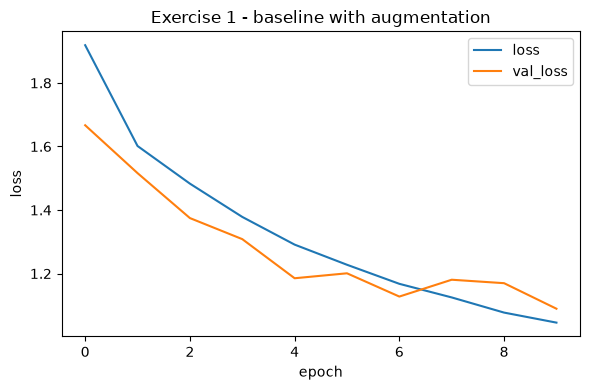

{'test_acc': 0.6144}


In [5]:
# To-Do: define augmentation and train
aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),                     # angle: mirrored view
    layers.RandomRotation(0.05),                         # angle: up to about 18 degrees
    layers.RandomTranslation(0.1, 0.1),                  # position: shift up to 10%
    layers.RandomZoom(0.1),                              # distance to the object
    layers.RandomBrightness(0.2, value_range=(0, 255)),  # lighting: darker / brighter
    layers.RandomContrast(0.2),                          # lighting: contrast
], name="augmentation")

tf.keras.utils.set_random_seed(42)
model_aug_e1 = tf.keras.Sequential([aug, model_e1])   # augmentation only runs during training
model_aug_e1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_e1 = model_aug_e1.fit(x_e1, y_e1, epochs=10, batch_size=64, validation_split=0.2, verbose=2)
plot_history(h_e1, title="Exercise 1 - baseline with augmentation")
test_acc = float(model_aug_e1.evaluate(x_test, y_test, verbose=0)[1])
print({"test_acc": round(test_acc, 4)})

**Robustness check.** Clean test accuracy does not tell me much about lighting, angle and position, so I also test both models on changed copies of the test set: darker, brighter, rotated by 15 degrees, shifted by 4 pixels and mirrored.

In [6]:
from scipy import ndimage

def to_uint8(a):
    return np.clip(a, 0, 255).astype("uint8")

x_float = x_test.astype("float32")
test_variants = {
    "clean": x_test,
    "darker (x0.6)": to_uint8(x_float * 0.6),
    "brighter (+60)": to_uint8(x_float + 60),
    "rotated 15 deg": to_uint8(ndimage.rotate(x_float, 15, axes=(1, 2), reshape=False, order=1, mode="nearest")),
    # shift right and down by 4 px: pad the top/left edge, then cut back to 32x32
    "shifted 4 px": np.pad(x_test, ((0, 0), (4, 0), (4, 0), (0, 0)), mode="edge")[:, :32, :32, :],
    "mirrored": x_test[:, :, ::-1, :],
}
rows = []
for name, xv in test_variants.items():
    a0 = model_noaug_e1.evaluate(xv, y_test, verbose=0)[1]
    a1 = model_aug_e1.evaluate(xv, y_test, verbose=0)[1]
    rows.append((name, a0, a1))
    print(f"{name:16s}  no aug: {a0:.4f}   with aug: {a1:.4f}   diff: {a1 - a0:+.4f}")

clean             no aug: 0.6834   with aug: 0.6144   diff: -0.0690


darker (x0.6)     no aug: 0.6654   with aug: 0.6315   diff: -0.0339


brighter (+60)    no aug: 0.6360   with aug: 0.6177   diff: -0.0183


rotated 15 deg    no aug: 0.6269   with aug: 0.6178   diff: -0.0091


shifted 4 px      no aug: 0.5420   with aug: 0.5705   diff: +0.0285


mirrored          no aug: 0.6854   with aug: 0.6190   diff: -0.0664


**Which augmentations help or hurt?** To see the effect of each type alone, I train the same CNN with only one kind of augmentation at a time. To keep it short on a CPU I use a 10,000 image subset and 6 epochs for each run, so these numbers are lower than the full runs above and only meant for comparing the types with each other.

In [7]:
# one augmentation type at a time, same subset, same epochs
import gc
sub = np.random.RandomState(1).choice(len(x_train), 10000, replace=False)
x_sub, y_sub = x_train[sub], y_train[sub]

aug_types = {
    "none": [],
    "flip": [layers.RandomFlip("horizontal")],
    "rotation": [layers.RandomRotation(0.05)],
    "shift + zoom": [layers.RandomTranslation(0.1, 0.1), layers.RandomZoom(0.1)],
    "lighting": [layers.RandomBrightness(0.2, value_range=(0, 255)), layers.RandomContrast(0.2)],
    "vertical flip": [layers.RandomFlip("vertical")],
}
ablation = {}
for name, aug_layers in aug_types.items():
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential(aug_layers + [make_cnn_e1()])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(x_sub, y_sub, epochs=6, batch_size=64, verbose=0)
    ablation[name] = float(m.evaluate(x_test, y_test, verbose=0)[1])
    print(f"{name:14s} test acc: {ablation[name]:.4f}")
    del m; tf.keras.backend.clear_session(); gc.collect()   # free memory between runs

none           test acc: 0.6192


flip           test acc: 0.6212


rotation       test acc: 0.5808


shift + zoom   test acc: 0.5461


lighting       test acc: 0.6062


vertical flip  test acc: 0.5104


**To-Do (written):** In 4 to 6 sentences explain how your augmentations improved robustness to lighting, angle, and position. Mention any augmentations that degraded accuracy and hypothesize why.

**My answer:** On my 20,000 image subset with 10 epochs, augmentation did **not** raise clean test accuracy: **68.3% without vs 61.4% with**. The curves explain it. Without augmentation the model already reaches 80.7% train vs 68.2% validation accuracy and starts to overfit, while the augmented model is still underfitting (62.8% train vs 61.5% validation), so it needs many more epochs to pay off. The robustness test shows what augmentation buys: the augmented model loses much less on changed images. On the 4 pixel shift it is better outright (57.1% vs 54.2%), on the 15 degree rotation it keeps its clean accuracy (61.8% vs 61.4% clean) while the plain model drops 5.7 points, and on darker / brighter images the gap between the two shrinks from 6.9 points to 3.4 and 1.8. In the one-at-a-time ablation (10,000 images, 6 epochs) only the horizontal flip helped a little (62.1% vs 61.9% with no augmentation). Lighting cost 1.3 points, rotation 3.8, shift + zoom 7.3 and vertical flip 10.9. I think vertical flip hurts because upside-down cars, ships and animals never appear in the test set, so the model spends capacity on views it will never see. Shift and zoom on a 32x32 image cut off a large part of the object, which makes the task much harder when there are only a few epochs to learn it.

# Exercise 2: Image classification with limited data

**As stated in the exercises**  
Use a small dataset with only a few hundred images. Train a CNN and explore overfitting prevention techniques such as augmentation, dropout, smaller models, and early stopping. Evaluate performance and analyze the impact of each technique.

### 2.1 Create a limited dataset

**PREFILLED**  
We simulate limited data by subsampling CIFAR-10. You may replace this with your own small folder dataset.

In [8]:
# PREFILLED: just execute - take 1000 train images and 200 test images
k_train, k_test = 1000, 200
sel_train = np.random.choice(len(x_train), k_train, replace=False)
sel_test  = np.random.choice(len(x_test),  k_test,  replace=False)
x_tr_small = x_train[sel_train]; y_tr_small = y_train[sel_train]
x_te_small = x_test[sel_test];   y_te_small = y_test[sel_test]
print("Small train:", x_tr_small.shape, "Small test:", x_te_small.shape)

Small train: (1000, 32, 32, 3) Small test: (200, 32, 32, 3)


### 2.2 Build a small model and add regularization

**To-Do:** Create a smaller CNN than Exercise 1. Add Dropout. Use EarlyStopping with `restore_best_weights=True`. Train on the limited set and compare with and without augmentation.

Epoch 1/50


13/13 - 1s - 91ms/step - accuracy: 0.1150 - loss: 2.3001 - val_accuracy: 0.1200 - val_loss: 2.2949


Epoch 2/50


13/13 - 0s - 17ms/step - accuracy: 0.1425 - loss: 2.2750 - val_accuracy: 0.1900 - val_loss: 2.2651


Epoch 3/50


13/13 - 0s - 17ms/step - accuracy: 0.1838 - loss: 2.2253 - val_accuracy: 0.2050 - val_loss: 2.1608


... (36 outputs left out)

Epoch 22/50


13/13 - 0s - 13ms/step - accuracy: 0.6612 - loss: 1.0030 - val_accuracy: 0.4750 - val_loss: 1.6415


Epoch 23/50


13/13 - 0s - 17ms/step - accuracy: 0.6525 - loss: 0.9816 - val_accuracy: 0.4700 - val_loss: 1.6326


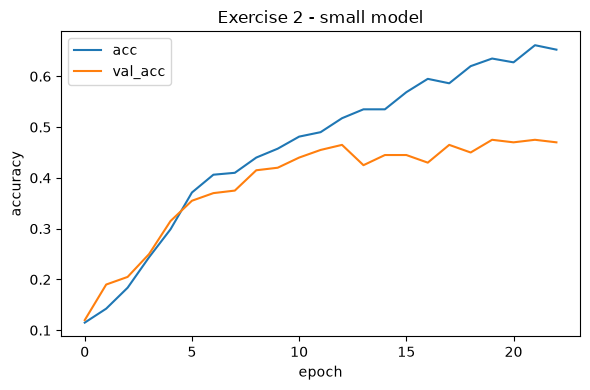

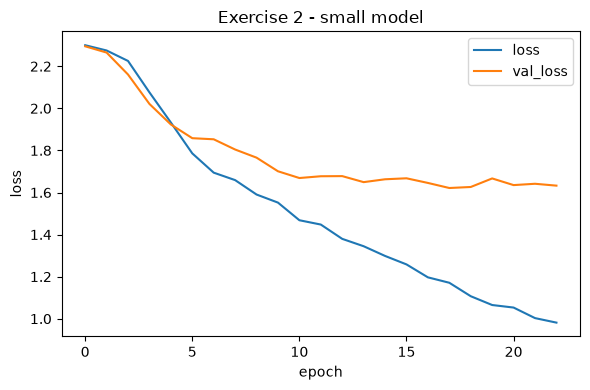

{'small_test_acc': 0.3799999952316284}


In [9]:
# To-Do: define small model and training with early stopping
tf.keras.utils.set_random_seed(42)
small = tf.keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, padding="same", activation="relu"),   # half the filters of Exercise 1
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.4),                                       # switch off 40% of the units while training
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
small.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cb = [tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
h_small = small.fit(x_tr_small, y_tr_small, epochs=50, batch_size=64, validation_split=0.2, callbacks=cb, verbose=2)
plot_history(h_small, title="Exercise 2 - small model")
print({"small_test_acc": float(small.evaluate(x_te_small, y_te_small, verbose=0)[1])})

**Impact of each technique.** I start from an unregularized model (the Exercise 1 architecture without dropout, 40 epochs, no early stopping) and add one technique at a time, then all of them together. The test set here has only 200 images, so one image is 0.5 points. That is why I also report accuracy on the full 10,000 CIFAR-10 test images, which is a much more stable number. The training data is still only the 800 images left after the validation split.

In [10]:
def make_large(dropout=0.0):
    # Exercise 1 architecture; dropout=0 means no regularization at all
    return tf.keras.Sequential([
        layers.Input(shape=(32, 32, 3)), layers.Rescaling(1./255),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dropout(dropout),
        layers.Dense(128, activation="relu"), layers.Dropout(dropout),
        layers.Dense(10, activation="softmax"),
    ])

def make_small(dropout=0.0):
    return tf.keras.Sequential([
        layers.Input(shape=(32, 32, 3)), layers.Rescaling(1./255),
        layers.Conv2D(16, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])

aug_small = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.05),
                                 layers.RandomTranslation(0.1, 0.1), layers.RandomZoom(0.1)])

def run_e2(name, builder, use_aug=False, early_stop=False, epochs=40):
    tf.keras.utils.set_random_seed(42)
    net = builder()
    m = tf.keras.Sequential([aug_small, net]) if use_aug else net
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)] if early_stop else []
    h = m.fit(x_tr_small, y_tr_small, epochs=epochs, batch_size=64, validation_split=0.2, callbacks=cbs, verbose=0)
    train_acc = m.evaluate(x_tr_small[:800], y_tr_small[:800], verbose=0)[1]   # the 800 images it trained on
    val_acc = m.evaluate(x_tr_small[800:], y_tr_small[800:], verbose=0)[1]
    res = {"run": name, "epochs": len(h.history["loss"]),
           "train_acc": round(train_acc, 3), "val_acc": round(val_acc, 3),
           "gap": round(train_acc - val_acc, 3),
           "test200_acc": round(m.evaluate(x_te_small, y_te_small, verbose=0)[1], 3),
           "test10k_acc": round(m.evaluate(x_test, y_test, verbose=0)[1], 3)}
    print(res)
    return res

e2_results = [
    run_e2("1 large, nothing", lambda: make_large(0.0)),
    run_e2("2 + augmentation", lambda: make_large(0.0), use_aug=True),
    run_e2("3 + dropout 0.4", lambda: make_large(0.4)),
    run_e2("4 smaller model", lambda: make_small(0.0)),
    run_e2("5 + early stopping", lambda: make_large(0.0), early_stop=True),
    run_e2("6 all together (small)", lambda: make_small(0.4), use_aug=True, early_stop=True, epochs=80),
]
import pandas as pd
pd.DataFrame(e2_results)

{'run': '1 large, nothing', 'epochs': 40, 'train_acc': 1.0, 'val_acc': 0.425, 'gap': 0.575, 'test200_acc': 0.435, 'test10k_acc': 0.417}


{'run': '2 + augmentation', 'epochs': 40, 'train_acc': 0.71, 'val_acc': 0.485, 'gap': 0.225, 'test200_acc': 0.465, 'test10k_acc': 0.447}


{'run': '3 + dropout 0.4', 'epochs': 40, 'train_acc': 0.971, 'val_acc': 0.455, 'gap': 0.516, 'test200_acc': 0.395, 'test10k_acc': 0.434}


{'run': '4 smaller model', 'epochs': 40, 'train_acc': 0.957, 'val_acc': 0.525, 'gap': 0.433, 'test200_acc': 0.385, 'test10k_acc': 0.421}


{'run': '5 + early stopping', 'epochs': 17, 'train_acc': 0.635, 'val_acc': 0.445, 'gap': 0.19, 'test200_acc': 0.405, 'test10k_acc': 0.393}


{'run': '6 all together (small)', 'epochs': 16, 'train_acc': 0.428, 'val_acc': 0.38, 'gap': 0.048, 'test200_acc': 0.35, 'test10k_acc': 0.363}


,run,epochs,train_acc,val_acc,gap,test200_acc,test10k_acc
0,"1 large, nothing",40,1.000,0.425,0.575,0.435,0.417
1,2 + augmentation,40,0.710,0.485,0.225,0.465,0.447
2,3 + dropout 0.4,40,0.971,0.455,0.516,0.395,0.434
3,4 smaller model,40,0.957,0.525,0.433,0.385,0.421
4,5 + early stopping,17,0.635,0.445,0.190,0.405,0.393
5,6 all together (small),16,0.428,0.380,0.048,0.350,0.363


**To-Do (written):** Report performance with and without Dropout and augmentation. Explain how each technique affected overfitting on the limited dataset.

**My answer:** The unregularized model simply memorizes the 800 training images: **100% train vs 42.5% validation** (a 57.5 point gap) and **41.7%** on the 10,000 test images. **Augmentation** was the strongest single technique. It cut the gap to 22.5 points and gave the best test accuracy (**44.7%, +3.0 points**), because it is the only technique that shows the model new-looking images. **Dropout 0.4** raised test accuracy to 43.4% (+1.7), but training accuracy stayed at 97%, so it only slowed the memorizing. The **smaller model** (about 7 times fewer weights) got almost the same accuracy (42.1%) with a smaller gap (43 points), so most of the big model's capacity was wasted on 800 images. **Early stopping** stopped after 17 epochs and closed the gap to 19 points, but test accuracy fell to 39.3%. With a validation set of only 200 images the validation loss is noisy, so it stopped too early. **All together** (small model + dropout + augmentation + early stopping) left almost no gap (4.8 points), but it is underfitting at 36.3%, because that much regularization needs far more than 16 epochs to learn anything. The template run (small model + dropout + early stopping, no augmentation) got 38.0% on the 200 test images. My takeaway: with very little data, augmentation actually helps, while the other techniques mostly shrink the gap, and stacking them all is too much. One image in the 200 image test set is 0.5 points, so I trust the 10,000 image column more.

**Learning point**  
Overfitting grows when parameter count is large relative to samples. Smaller models, dropout, and early stopping reduce variance. This is analogous to regularization in linear models.

# Exercise 3: Using a pre-trained model for feature extraction

**As stated in the exercises**  
Choose a dataset. Use a pre-trained CNN such as MobileNet or ResNet to extract features, then train a simple classifier on top. Compare with training a CNN from scratch in accuracy and time.

### 3.1 Build a frozen feature extractor

**PREFILLED**  
MobileNetV2 is used here since it is lightweight and fast. Inputs are resized to 160x160 to match the backbone expectations. The base is frozen to act as a feature extractor.

**Small fix to the prefilled cell:** in Keras 3 (the version Colab installs now) `tf.image.resize` cannot be applied to a symbolic `layers.Input` and the cell stops with *"A KerasTensor cannot be used as input to a TensorFlow function"*. I replaced it with the `layers.Resizing` layer, which does the same resize. The rest of the cell is unchanged.

In [11]:
# PREFILLED: just execute - feature extractor builder
IMG_SIZE_FE = (160,160)
base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE_FE[0], IMG_SIZE_FE[1], 3),
                                         include_top=False, weights="imagenet")
base.trainable = False
preproc = tf.keras.applications.mobilenet_v2.preprocess_input

def build_feature_model(num_classes=10):
    inputs = layers.Input(shape=(32,32,3))  # CIFAR-10 size
    x = layers.Resizing(*IMG_SIZE_FE)(inputs)   # was tf.image.resize(inputs, IMG_SIZE_FE), which fails in Keras 3
    x = preproc(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

feature_model = build_feature_model(10)
feature_model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3.2 Train and compare

**To-Do:** Train the feature extraction model on CIFAR-10 and record time and accuracy. Compare to the Exercise 1 baseline. State which approach is faster and which reached higher accuracy for the same budget.

Running every image through MobileNetV2 at 160x160 is slow on a CPU, so I train both approaches on the **same 5,000 image subset** (4,000 for training, 1,000 for validation) and test both on the full 10,000 test images. I give them the same budget of 5 epochs, and I also train the scratch CNN longer (20 epochs) because its epochs are much cheaper.

Epoch 1/5


63/63 - 24s - 375ms/step - accuracy: 0.6880 - loss: 0.9612 - val_accuracy: 0.8040 - val_loss: 0.5877


Epoch 2/5


63/63 - 40s - 638ms/step - accuracy: 0.8487 - loss: 0.4467 - val_accuracy: 0.8030 - val_loss: 0.5784


Epoch 3/5


63/63 - 13s - 204ms/step - accuracy: 0.8900 - loss: 0.3342 - val_accuracy: 0.8130 - val_loss: 0.5595


Epoch 4/5


63/63 - 7s - 111ms/step - accuracy: 0.9170 - loss: 0.2640 - val_accuracy: 0.8180 - val_loss: 0.5606


Epoch 5/5


63/63 - 6s - 102ms/step - accuracy: 0.9392 - loss: 0.2107 - val_accuracy: 0.8030 - val_loss: 0.6143


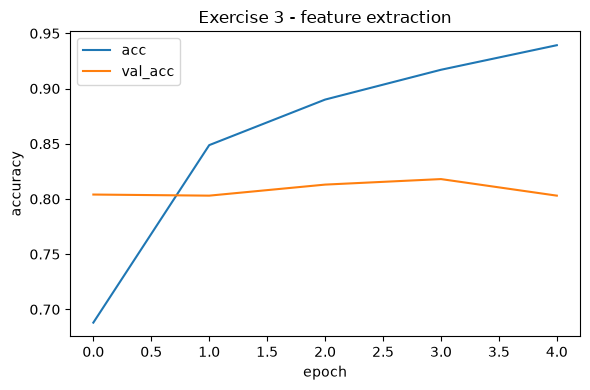

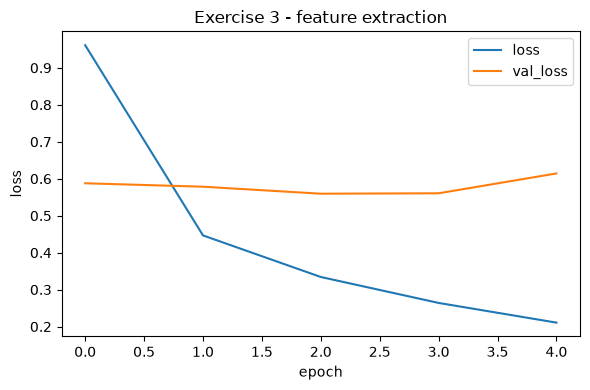

{'feature_extraction_test_acc': 0.817, 'train_time_s': 90.1}


In [12]:
# To-Do: train feature extractor and compare to scratch
import time
fe_idx = np.random.RandomState(1).choice(len(x_train), 5000, replace=False)
x_fe, y_fe = x_train[fe_idx], y_train[fe_idx]

t0 = time.time()
h_fe = feature_model.fit(x_fe, y_fe, epochs=5, batch_size=64, validation_split=0.2, verbose=2)
t1 = time.time() - t0
plot_history(h_fe, title="Exercise 3 - feature extraction")
acc_fe = float(feature_model.evaluate(x_test, y_test, verbose=0)[1])
print({"feature_extraction_test_acc": round(acc_fe, 4), "train_time_s": round(t1,1)})

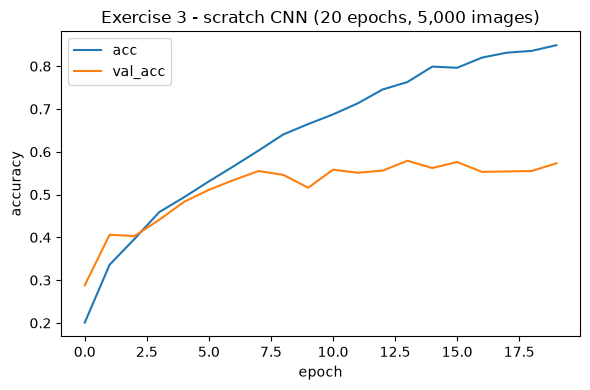

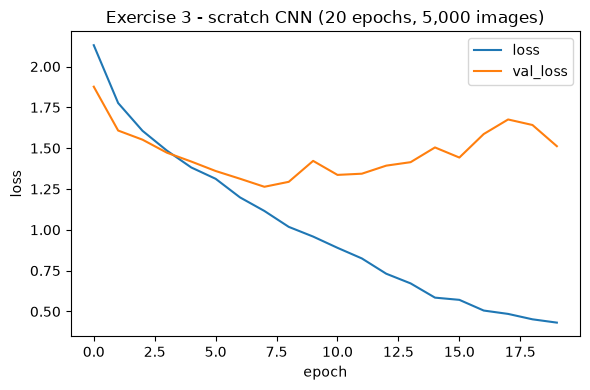

MobileNetV2 features, 5 epochs   test acc: 0.8170   train time:   90.1 s
scratch CNN, 5 epochs            test acc: 0.4749   train time:    6.0 s
scratch CNN, 20 epochs           test acc: 0.5538   train time:   48.1 s
For reference, Exercise 1 scratch CNN on 20,000 images (no aug, 10 epochs): 0.6834


In [13]:
# the same CNN as Exercise 1, from scratch, on the same 5,000 images
e3 = {"MobileNetV2 features, 5 epochs": (acc_fe, t1)}
for ep in [5, 20]:
    tf.keras.utils.set_random_seed(42)
    scratch = make_cnn_e1()
    t0 = time.time()
    h_sc = scratch.fit(x_fe, y_fe, epochs=ep, batch_size=64, validation_split=0.2, verbose=0)
    t_sc = time.time() - t0
    e3[f"scratch CNN, {ep} epochs"] = (float(scratch.evaluate(x_test, y_test, verbose=0)[1]), t_sc)
plot_history(h_sc, title="Exercise 3 - scratch CNN (20 epochs, 5,000 images)")

for k, (acc, t) in e3.items():
    print(f"{k:32s} test acc: {acc:.4f}   train time: {t:6.1f} s")
print(f"For reference, Exercise 1 scratch CNN on 20,000 images (no aug, 10 epochs): {test_acc_noaug:.4f}")

**To-Do (written):** Summarize the comparison between training from scratch and feature extraction in 4 to 6 sentences, focusing on training time and accuracy.

**My answer:** Feature extraction wins clearly on accuracy. MobileNetV2 features plus a small dense head reached **81.7%** on the 10,000 test images after 5 epochs on only 4,000 training images. The same scratch CNN on the same images got **47.5% after 5 epochs and 55.4% after 20**, and even the Exercise 1 scratch CNN trained on 16,000 images only reached 68.3%. The reason is that the ImageNet features (edges, textures, object parts) already fit CIFAR objects, so only the small head (about 165,000 weights) has to learn. On training time, the scratch CNN is much cheaper per epoch on a CPU: **90 s for 5 feature-extraction epochs vs 6 s for 5 scratch epochs** (48 s for 20; the CPU was shared with another job, so these timings are rough). Every epoch has to push each image through MobileNetV2 at 160x160, which is 25 times more pixels than 32x32. So for the same time budget the frozen backbone still gives far higher accuracy. It would be even faster to run the images through the backbone **once**, save the features, and train the head on them for many epochs. The head also overfits a bit (93.9% train vs 80.3% validation at epoch 5), so dropout in the head would be my next step.

**Learning point**  
Transfer learning reuses features from large scale training. For small data or limited compute, frozen backbones deliver strong baselines quickly.

# Exercise 4: Visualizing CNN filters

**As stated in the exercises**  
Train a CNN and then visualize filters learned in the first convolution. Analyze what patterns they detect such as edges or textures, and how visualization helps you understand model behavior.

![image.png](https://github.com/user-attachments/assets/8ddeb5e1-9e3c-41cf-976a-efd962e715f9)

### 4.1 Train or reuse a model

**PREFILLED**  
We reuse the baseline CNN from Exercise 1 if available. Otherwise you can train a small model here.

In [14]:
# PREFILLED: just execute - reuse model_e1 if defined, else create a tiny model and train briefly
if 'model_e1' not in globals():
    model_e1 = tf.keras.Sequential([
        layers.Input(shape=(32,32,3)),
        layers.Rescaling(1./255),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv_first"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation="softmax"),
    ])
    model_e1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model_e1.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.2, verbose=2)
else:
    # ensure the first conv layer has a known name
    for l in model_e1.layers:
        if isinstance(l, layers.Conv2D) and not l.name:
            l._name = "conv_first"
            break
print("Model ready for visualization.")

Model ready for visualization.


### 4.2 Visualize first layer filters
Here's an intuitive reminder on how to think about filters' mechanism
![](./figs/1.gif)


**To-Do:** Implement a function that finds the first Conv2D layer, retrieves its kernel weights, normalizes them to 0 to 1, and renders them in a grid.

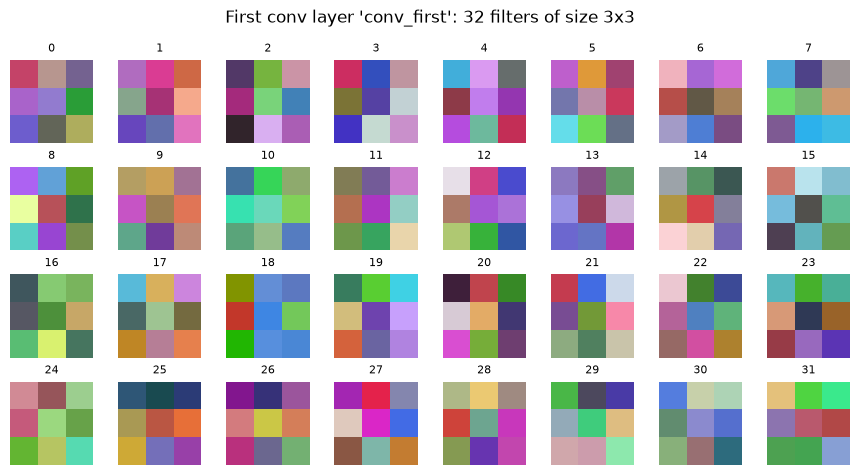

In [15]:
# To-Do: implement filter visualization
import math
def show_first_conv_filters(model, layer_name_hint="conv"):
    convs = [l for l in model.layers if isinstance(l, layers.Conv2D)]
    named = [l for l in convs if layer_name_hint in l.name]
    conv = (named or convs)[0]                     # first Conv2D (prefer one whose name has the hint)
    w, b = conv.get_weights()                      # w shape: (3, 3, 3, n_filters)
    w = (w - w.min()) / (w.max() - w.min())        # scale all weights to 0..1 so I can show them as RGB
    n = w.shape[-1]; cols = 8; rows = math.ceil(n / cols)
    plt.figure(figsize=(cols * 1.1, rows * 1.2))
    for i in range(n):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(w[:, :, :, i], interpolation="nearest")   # one 3x3 RGB filter
        plt.title(str(i), fontsize=8); plt.axis("off")
    plt.suptitle(f"First conv layer '{conv.name}': {n} filters of size {w.shape[0]}x{w.shape[1]}")
    plt.tight_layout(); plt.show()
    return conv

conv_first = show_first_conv_filters(model_e1, layer_name_hint="conv")

A 3x3 filter is tiny, so I also look at what the filters **do**: the feature maps of the first layer for one test image. Bright means the filter reacts strongly there.

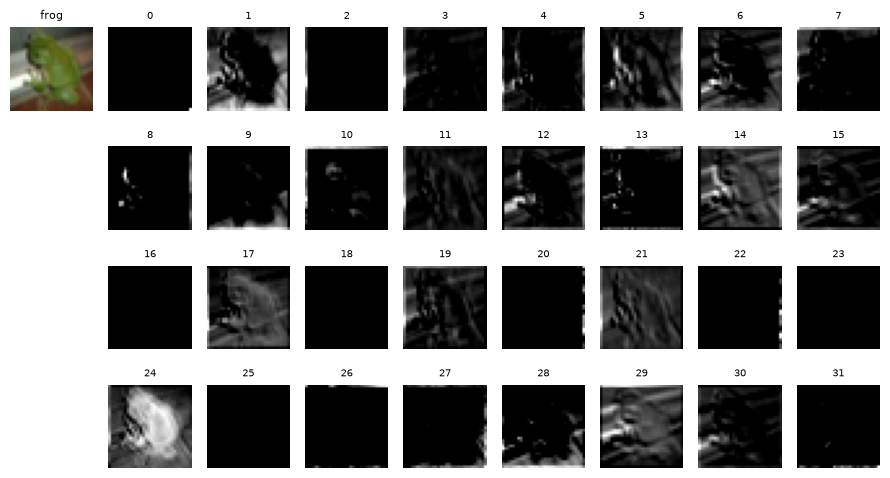

most color-sensitive filters: [18 27 19 31  8]
strongest vertical-edge filters: [ 8  2 18 20  0]
strongest horizontal-edge filters: [22 29 23 20 27]


In [16]:
# feature maps of the first conv layer for one test image
act_model = models.Model(model_e1.inputs, conv_first.output)
img = x_test[7:8]
maps = act_model.predict(img, verbose=0)[0]          # shape (32, 32, 32)
plt.figure(figsize=(9, 5))
plt.subplot(4, 9, 1); plt.imshow(img[0]); plt.title(class_names_c10[y_test[7]], fontsize=8); plt.axis("off")
for i in range(32):
    plt.subplot(4, 9, i + 2 + i // 8)                # leave the first column of each row free
    plt.imshow(maps[:, :, i], cmap="gray"); plt.title(str(i), fontsize=7); plt.axis("off")
plt.tight_layout(); plt.show()

# simple numbers per filter: how colorful it is and how much it changes from left to right / top to bottom
w = conv_first.get_weights()[0]
color_spread = w.std(axis=2).mean(axis=(0, 1))                 # high = reacts to color differences
horiz = np.abs(w[:, 2, :, :] - w[:, 0, :, :]).mean(axis=(0, 1))  # right column vs left column -> vertical edges
vert = np.abs(w[2, :, :, :] - w[0, :, :, :]).mean(axis=(0, 1))   # bottom row vs top row -> horizontal edges
print("most color-sensitive filters:", np.argsort(-color_spread)[:5])
print("strongest vertical-edge filters:", np.argsort(-horiz)[:5])
print("strongest horizontal-edge filters:", np.argsort(-vert)[:5])

**To-Do (written):** Describe the kinds of patterns the filters detect such as oriented edges, color blobs, or simple textures. Explain how this helps interpret early feature extraction in CNNs.

**My answer:** The first layer filters are only 3x3 pixels across 3 color channels, so they look like small color patches. They fall into two groups. Some are **color detectors**, like filters 18, 27, 19, 31 and 8, which have the largest differences between their red, green and blue weights. Others are **edge detectors**, where one side of the 3x3 square differs from the other: filters 8, 2, 18, 20 and 0 respond most to vertical edges (left vs right column), and 22, 29, 23, 20 and 27 to horizontal edges (top vs bottom row). The feature maps for the frog make this concrete. Filter 24 lights up the whole green body (a color blob detector), filters 14 and 29 follow the diagonal edges of the branch, and filters 1 and 5 react to the bright background and the outline. Many maps are completely dark for this image, either because the color or direction they look for isn't there, or because the filter never activates (a "dead" ReLU filter). This matches the theory that the first layer finds simple edges, colors and textures, and deeper layers combine them into object parts. The visualization helps me check that training worked (smooth, structured filters and not random noise) and see which simple signals, like color, the model relies on from the start.